# Phoenix synthetic pricing : a numerical example

In this notebook, we price a synthetic Phoenix autocall on the CAC 40 with a Heston model calibrated on the market, then we study its sensitivities and the features that can be added to the product. The base case has the same dates and barriers as the Athena of `Athena/athena_synthetic_pricing.ipynb`, so that the two products can be compared.

**Base case**

| Term | Value |
|---|---|
| Underlying | CAC 40 index (price return, dividends not reinvested) |
| Pricing date | 12 February 2025 (market data of the calibration) |
| Maturity | 4 years |
| Observations | quarterly (16 dates), all callable |
| Coupon | 6% p.a., i.e. 1.5% per quarter, paid if the index is at or above the coupon barrier |
| Coupon barrier | 70% of the initial level, with memory |
| Autocall barrier | 100% of the initial level |
| Protection barrier | 60%, European (observed at maturity only) |
| Nominal | 100 |

**Payoff.** At each observation date $t_k$, if $S_{t_k} \geq 70\% \, S_{ref}$ the coupon $c \, (t_k - t_{k-1})$ is paid, together with the coupons missed since the last payment (memory). If moreover $S_{t_k} \geq 100\% \, S_{ref}$, the note is redeemed at 100. If it is never called, it is redeemed at 100 when $S_T \geq 60\% \, S_{ref}$, and at $100 \, S_T / S_{ref}$ otherwise.

In [1]:
import os, sys
sys.path.append(os.path.abspath(os.path.join("..", "..")))                   # repo root: Equity_Models package
sys.path.append(os.path.abspath(os.path.join("..", "..", "Equity_Models")))  # flat imports inside Equity_Models
sys.path.append(os.path.abspath(".."))                                       # Products: market.py, notes_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston
from phoenix import Phoenix                                                  # Products/Phoenix/phoenix.py (self-contained)
from Equity_Models.monte_carlo import MonteCarloPricer
from Equity_Models.greeks import Greeks, bump_vol, bump_carry, bump_rate, plot_greeks_bars, plot_greek_profiles
from notes_analysis import plot_redemption_profiles, plot_call_probabilities, plot_scenarios

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Model

We use the Heston model calibrated on the CAC 40 implied volatility surface (`market.cac40_heston`). The paths are simulated on a weekly grid : the observation dates are quarterly and an American protection would use the Brownian bridge, so a daily grid is only needed for daily observations.

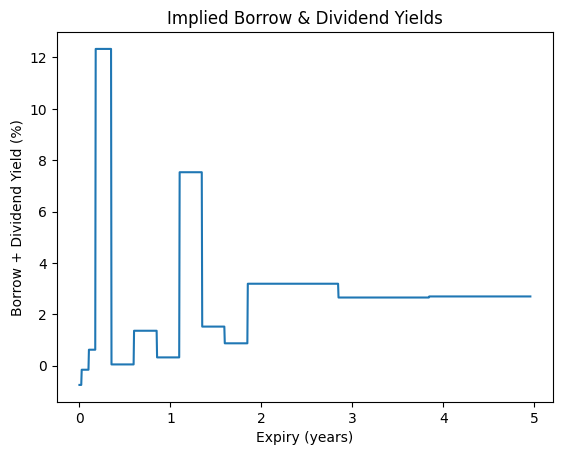

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [2]:
mkt = cac40_heston()
heston, S0 = mkt.heston, mkt.S0

pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42)
daily_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)

## 2. Pricing

`report` gathers the terms of the contract, the price (with its 95% Monte Carlo confidence interval), the fair coupon (the coupon that prices the note at par) and the scenario statistics.

In [3]:
base = Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6)
table, calls = base.report(pricer, heston, name="Base case", by_date=True)
table

Base case
Contract  maturity (years)                              4
          number of observations                       16
          observation frequency (years)              0.25
          coupon (% p.a.)                               6
          first coupon barrier (%)                     70
          last coupon barrier (%)                      70
          memory                                     True
          first autocall barrier (%)                  100
          last autocall barrier (%)                   100
          step-down per observation (%)                 0
          first call date (years)                    0.25
          protection barrier (%)                       60
          protection type                        european
          redemption if knocked-in               standard
          capital guaranteed (%)                        0
          buffer (%)                                    0
          range accrual (%)                          none
          duo barrier (%)                            none
          duo coupon ratio                           none
          look back                                  none
          nominal                                     100
Pricing   price                                   99.9631
          95% confidence (+/-)                  0.0985235
          price (% nominal)                       99.9631
          fair coupon (% p.a.)                    6.04354
Scenarios probability to reach maturity            0.1329
          probability of a capital loss           0.05218
          expected loss at maturity (% nominal)   3.05192
          expected life (years)                   1.03247
          expected number of coupons              3.28464
          expected coupon paid (% nominal)        5.23461

Probability of a call at each observation date, and cumulated :

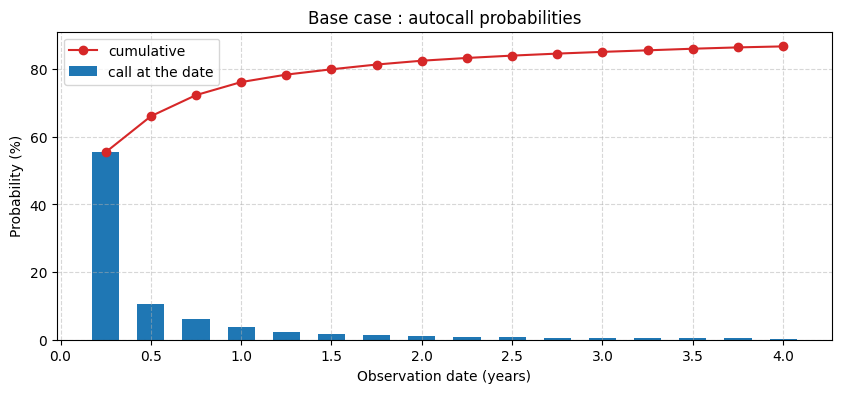

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(calls.index, 100 * calls["call probability"], width=0.15, label="call at the date")
ax.plot(calls.index, 100 * calls["cumulative"], "o-", color="tab:red", label="cumulative")
ax.set_xlabel("Observation date (years)")
ax.set_ylabel("Probability (%)")
ax.set_title("Base case : autocall probabilities")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()

Some simulated scenarios, grouped by outcome (called early, redeemed at par at maturity, capital loss), with the coupon barrier :

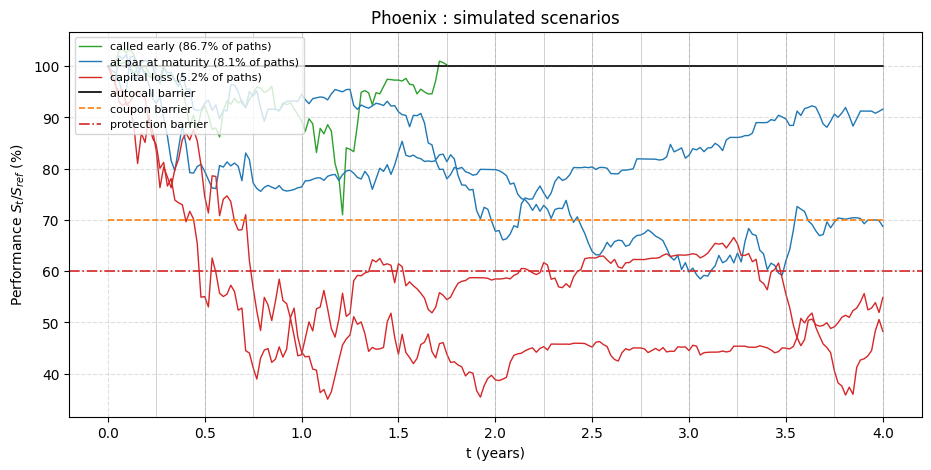

In [5]:
plot_scenarios(pricer, heston, base)

**Reading.** The call probabilities are exactly the ones of the Athena with the same autocall barrier : the coupon does not change the call rule. What changes is the way the coupon is paid : the Phoenix pays a coupon at every date where the index is above 70%, even if the note is not called. The investor receives coupons in scenarios where the Athena pays nothing (index between 70% and 100%), so the coupon needed to price the note at par is much lower than the Athena's. The investor is still short a down-and-in put, with a loss jump from 100 to 60 at the protection barrier.

## 3. Sensitivities

To compare a variant with the base case, `compare` prices it, keeps its report in `reports` (used in the summary of section 4) and only displays the terms of the contract that differ from the base case.

In [6]:
reports = {"Base case": table}
BASE_TERMS = dict(frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6)

def compare(name, note, note_pricer=pricer):
    """ Report of note next to the base case, with only the contract terms that differ. """
    reports[name] = note.report(note_pricer, heston, name=name)
    out = pd.concat([table, reports[name]], axis=1)
    contract = out.loc["Contract"].astype(str)
    changed = [("Contract", k) for k in contract.index[contract.nunique(axis=1) > 1]]
    return out.loc[changed + [i for i in out.index if i[0] != "Contract"]]


def sweep(parameter, values, **terms):
    """ Fair coupon and scenario statistics of the base case when one parameter moves. """
    rows = {}
    for x in values:
        note = Phoenix(4.0, S0, 0.06, **{**BASE_TERMS, **terms, parameter: x})
        stats = note.statistics(pricer, heston)
        rows[x] = {"fair coupon (% p.a.)": 100 * note.fair_coupon(pricer, heston),
                   "probability of a capital loss (%)": 100 * stats["probability of a capital loss"],
                   "expected loss (% nominal)": stats["expected loss at maturity (% nominal)"],
                   "expected life (years)": stats["expected life (years)"],
                   "expected number of coupons": stats["expected number of coupons"]}
    return pd.DataFrame(rows).T.rename_axis(parameter)


def plot_sweep(df, title):
    fig, axes = plt.subplots(1, len(df.columns), figsize=(4.2 * len(df.columns), 3.4))
    for ax, column in zip(axes, df.columns):
        ax.plot(100 * df.index, df[column], "o-")
        ax.set_title(column, fontsize=10)
        ax.set_xlabel(f"{df.index.name} (%)")
        ax.grid(True, linestyle="--", alpha=0.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 3.1 Protection barrier

In [7]:
compare("Protection 80%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.8))

Base case Protection 80%
Contract  protection barrier (%)                       60             80
Pricing   price                                   99.9631        98.7678
          95% confidence (+/-)                  0.0985235       0.100205
          price (% nominal)                       99.9631        98.7678
          fair coupon (% p.a.)                    6.04354         7.4547
Scenarios probability to reach maturity            0.1329         0.1329
          probability of a capital loss           0.05218        0.09568
          expected loss at maturity (% nominal)   3.05192        4.34222
          expected life (years)                   1.03247        1.03247
          expected number of coupons              3.28464        3.28464
          expected coupon paid (% nominal)        5.23461        5.23461

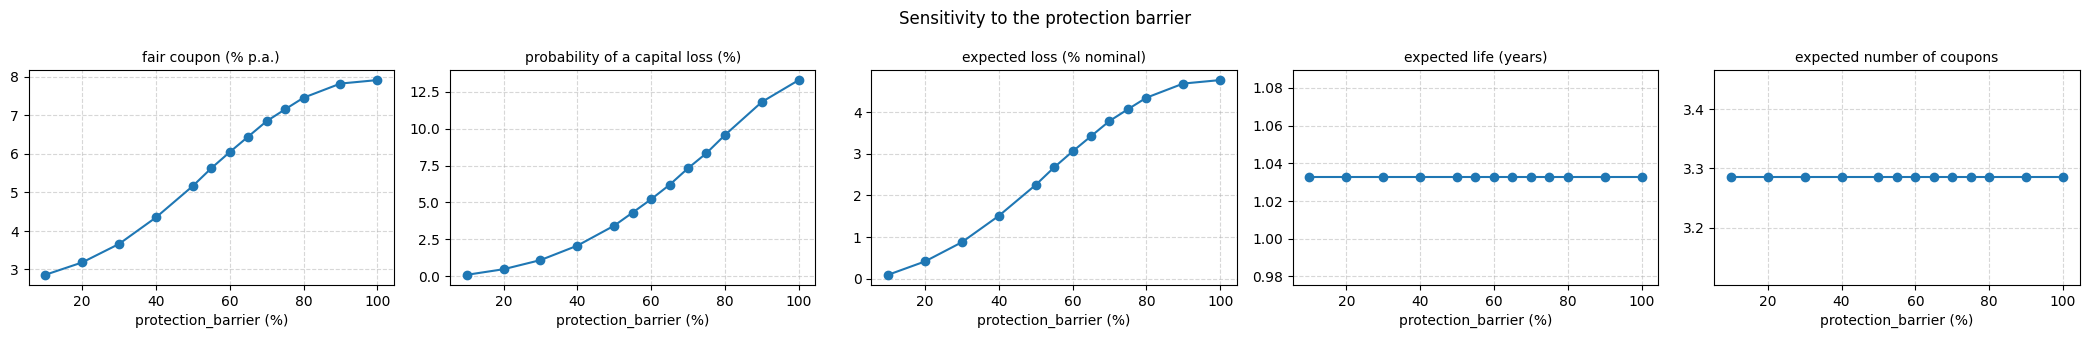

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years),expected number of coupons
protection_barrier,,,,,
0.1,2.85976,0.096,0.0897484,1.03247,3.28464
0.2,3.18116,0.476,0.410783,1.03247,3.28464
0.3,3.66081,1.094,0.871943,1.03247,3.28464
0.4,4.34791,2.072,1.50469,1.03247,3.28464
0.5,5.16452,3.428,2.24682,1.03247,3.28464
0.55,5.62541,4.316,2.66903,1.03247,3.28464
0.6,6.04354,5.218,3.05192,1.03247,3.28464
0.65,6.44602,6.194,3.4177,1.03247,3.28464
0.7,6.84591,7.318,3.78266,1.03247,3.28464


In [8]:
protection_sweep = sweep("protection_barrier", [0.1, 0.2, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0])
plot_sweep(protection_sweep, "Sensitivity to the protection barrier")
protection_sweep

A higher protection barrier means that the investor sells a more valuable down-and-in put : the capital is lost more often, and the fair coupon increases to pay for it. The call probabilities, the expected life and the coupons paid do not move, since the protection only matters at maturity.

### 3.2 Autocall barrier

In [9]:
compare("Autocall 110%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.1, protection_barrier=0.6))

Base case Autocall 110%
Contract  first autocall barrier (%)                  100           110
          last autocall barrier (%)                   100           110
Pricing   price                                   99.9631         101.4
          95% confidence (+/-)                  0.0985235      0.105746
          price (% nominal)                       99.9631         101.4
          fair coupon (% p.a.)                    6.04354       5.30854
Scenarios probability to reach maturity            0.1329       0.37564
          probability of a capital loss           0.05218        0.1048
          expected loss at maturity (% nominal)   3.05192       6.03887
          expected life (years)                   1.03247       2.39018
          expected number of coupons              3.28464       8.03534
          expected coupon paid (% nominal)        5.23461       12.6113

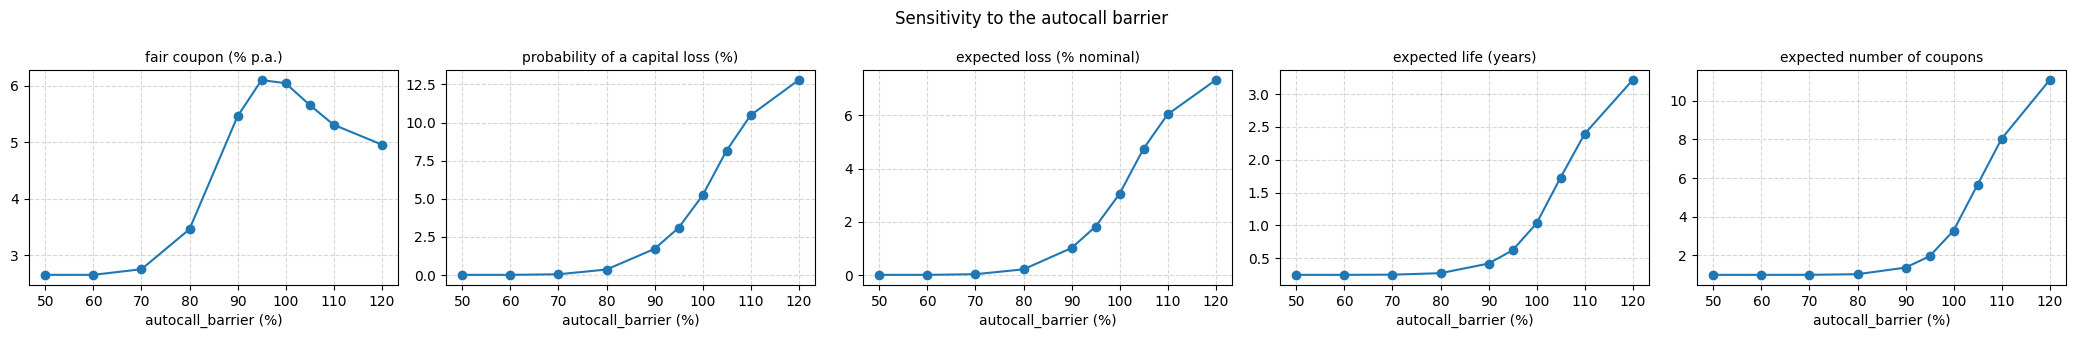

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years),expected number of coupons
autocall_barrier,,,,,
0.5,2.65318,0,0,0.25,0.99832
0.6,2.65328,0,0,0.25001,0.99832
0.7,2.75269,0.038,0.0242467,0.252665,0.99952
0.8,3.46056,0.348,0.207147,0.27537,1.03076
0.9,5.45806,1.704,1.00956,0.42151,1.373
0.95,6.09902,3.084,1.81631,0.62259,1.95956
1,6.04354,5.218,3.05192,1.03247,3.28464
1.05,5.66063,8.16,4.75168,1.72821,5.6655
1.1,5.30854,10.48,6.03887,2.39018,8.03534


In [10]:
autocall_sweep = sweep("autocall_barrier", [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2])
plot_sweep(autocall_sweep, "Sensitivity to the autocall barrier")
autocall_sweep

A higher autocall barrier makes the call less likely : the note lives longer and more paths reach maturity and are exposed to the put. Unlike the Athena, the fair coupon does not increase : above 95%, it even decreases (5.31% at 110% against 6.04% at 100%). A longer life means more coupon dates, so each point of coupon is worth more to the investor (8.0 expected coupons at 110% against 3.3 at 100%), and this effect dominates the larger exposure to the put. For the Athena, the coupon is paid only once, at the call, so a longer life only adds risk.

### 3.3 Coupon barrier

In [11]:
compare("Coupon barrier 90%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.9, autocall_barrier=1.0, protection_barrier=0.6))

Base case Coupon barrier 90%
Contract  first coupon barrier (%)                     70                 90
          last coupon barrier (%)                      70                 90
Pricing   price                                   99.9631            98.7824
          95% confidence (+/-)                  0.0985235           0.105138
          price (% nominal)                       99.9631            98.7824
          fair coupon (% p.a.)                    6.04354            7.87232
Scenarios probability to reach maturity            0.1329             0.1329
          probability of a capital loss           0.05218            0.05218
          expected loss at maturity (% nominal)   3.05192            3.05192
          expected life (years)                   1.03247            1.03247
          expected number of coupons              3.28464            2.03178
          expected coupon paid (% nominal)        5.23461             4.0089

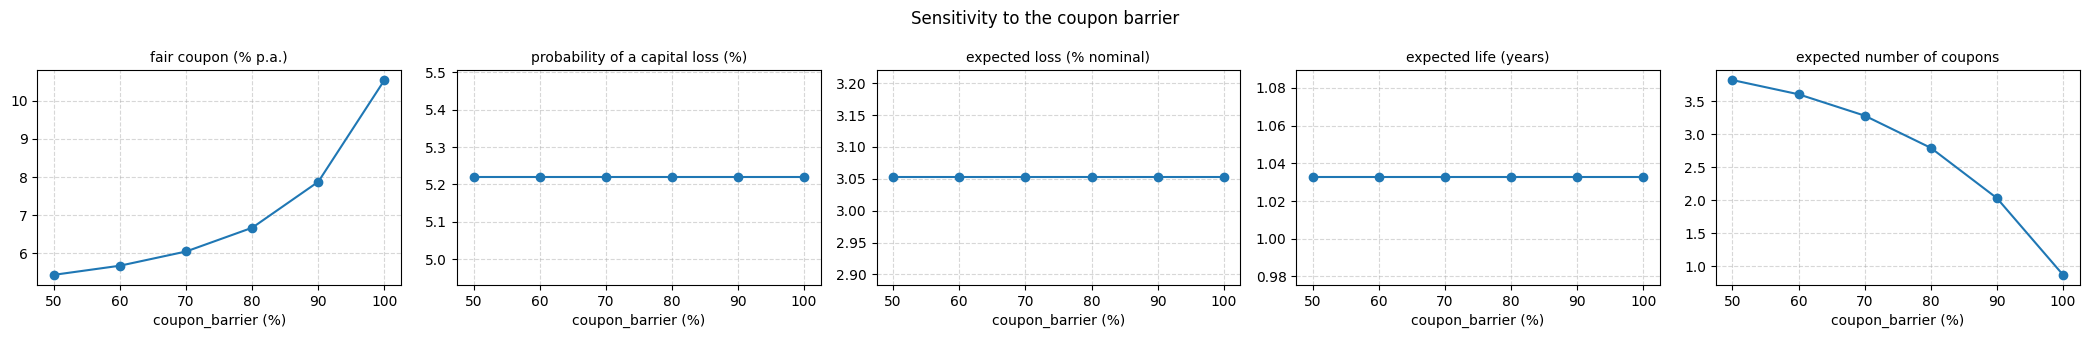

,fair coupon (% p.a.),probability of a capital loss (%),expected loss (% nominal),expected life (years),expected number of coupons
coupon_barrier,,,,,
0.5,5.4311,5.218,3.05192,1.03247,3.82518
0.6,5.67092,5.218,3.05192,1.03247,3.60922
0.7,6.04354,5.218,3.05192,1.03247,3.28464
0.8,6.66633,5.218,3.05192,1.03247,2.79552
0.9,7.87232,5.218,3.05192,1.03247,2.03178
1,10.5382,5.218,3.05192,1.03247,0.8671


In [12]:
coupon_sweep = sweep("coupon_barrier", [0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plot_sweep(coupon_sweep, "Sensitivity to the coupon barrier")
coupon_sweep

A higher coupon barrier pays fewer coupons, so the fair coupon increases. The call and the loss do not depend on the coupon barrier. With memory, a coupon barrier equal to the autocall barrier (100%) gives back exactly the snowball Athena : the coupons are only paid at the call, all together, and the fair coupon is the Athena's (10.54%).

### 3.4 Market parameters

The note is now kept unchanged (coupon 6%, barriers of the base case) and the market moves : volatility, dividends, rates, issuer spread, maturity and skew. `market_sweep` prices the base case under each scenario.

In [13]:
import copy

class SpreadPricer(MonteCarloPricer):
    """ Discounts the cash flows of the note at r(t) + spread (issuer credit / funding), the drift staying at r(t) - q(t).
    The control variate (a put discounted at r) is switched off, since its exact price would not match. """
    def __init__(self, spread, **kwargs):
        super().__init__(control_variate=False, **kwargs)
        self.spread = spread

    def discount_factors(self, model, maturity, M):
        grid = np.linspace(0.0, maturity, M + 1)
        return super().discount_factors(model, maturity, M) * np.exp(-self.spread * grid)


def market_sweep(name, scenarios, note=None):
    """ Price at 6%, fair coupon and scenario statistics of note (base case by default) under each scenario
    {x: (model, pricer)}. """
    rows = {}
    for x, (model, p) in scenarios.items():
        n = base if note is None else note(x)
        stats = n.statistics(p, model)
        rows[x] = {"price at 6%": p.price(model, n).price,
                   "fair coupon (% p.a.)": 100 * n.fair_coupon(p, model),
                   "call at 1st date (%)": 100 * list(stats["call probability by date"].values())[0],
                   "probability of a capital loss (%)": 100 * stats["probability of a capital loss"],
                   "expected life (years)": stats["expected life (years)"],
                   "expected number of coupons": stats["expected number of coupons"]}
    return pd.DataFrame(rows).T.rename_axis(name)


def plot_market_sweep(df, title, columns=("price at 6%", "fair coupon (% p.a.)", "probability of a capital loss (%)", "expected number of coupons")):
    fig, axes = plt.subplots(1, len(columns), figsize=(4.2 * len(columns), 3.4))
    for ax, column in zip(axes, columns):
        ax.plot(df.index, df[column], "o-")
        ax.set_title(column, fontsize=10)
        ax.set_xlabel(df.index.name)
        ax.grid(True, linestyle="--", alpha=0.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def with_rho(rho):
    """ Copy of the calibrated Heston model with another spot-variance correlation. """
    model = copy.copy(heston)
    model.rho = rho
    return model

#### Volatility

$\sqrt{v_0}$ and $\sqrt{\theta}$ are shifted together, from $-3$ to $+3$ vol points.

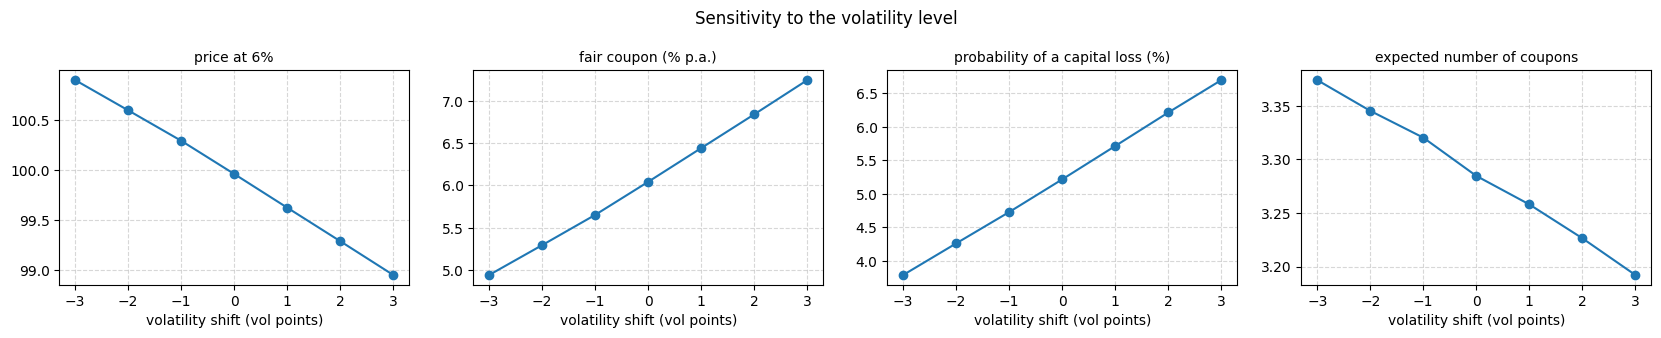

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),expected number of coupons
volatility shift (vol points),,,,,,
-3,100.902,4.94307,56.818,3.79,0.99673,3.37406
-2,100.6,5.29556,56.326,4.262,1.00846,3.34536
-1,100.295,5.65286,55.864,4.73,1.02161,3.32034
0,99.9631,6.04354,55.428,5.218,1.03247,3.28464
1,99.6262,6.44206,55.076,5.716,1.04489,3.25802
2,99.2909,6.84025,54.63,6.216,1.05673,3.22644
3,98.953,7.2448,54.17,6.7,1.06795,3.19216


In [14]:
vol_sweep = market_sweep("volatility shift (vol points)", {d: (bump_vol(heston, d / 100), pricer) for d in [-3, -2, -1, 0, 1, 2, 3]})
plot_market_sweep(vol_sweep, "Sensitivity to the volatility level")
vol_sweep

#### Dividends

Parallel shift of the borrow + dividend yield $q(t)$, from $-1\%$ to $+1\%$.

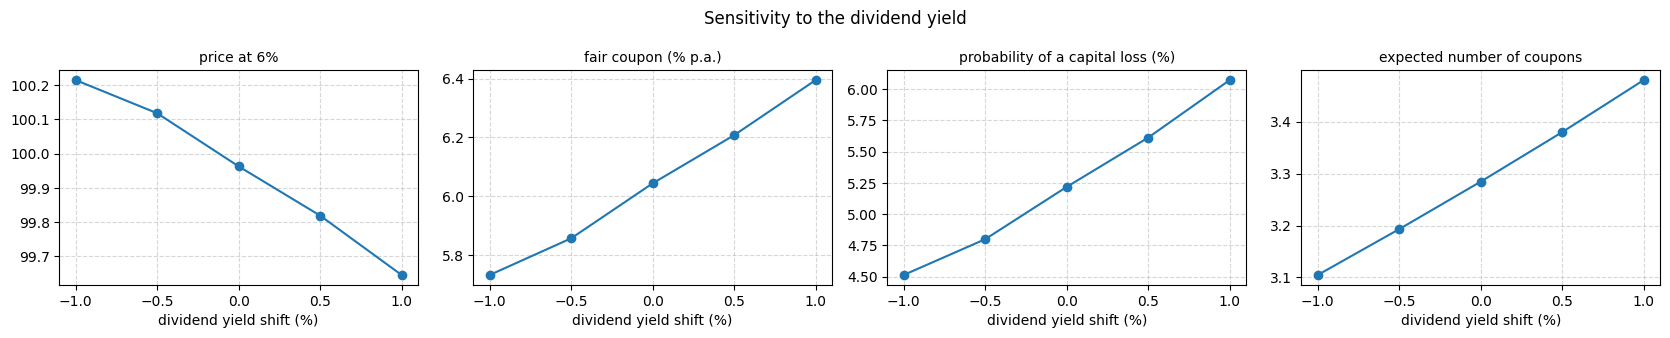

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),expected number of coupons
dividend yield shift (%),,,,,,
-1,100.215,5.73154,56.952,4.514,0.96352,3.10474
-0.5,100.118,5.85634,56.198,4.8,0.99699,3.19314
0,99.9631,6.04354,55.428,5.218,1.03247,3.28464
0.5,99.8192,6.20749,54.67,5.612,1.06878,3.38014
1,99.6458,6.39512,53.88,6.072,1.10771,3.48042


In [15]:
dividend_sweep = market_sweep("dividend yield shift (%)", {d: (bump_carry(heston, d / 100), pricer) for d in [-1, -0.5, 0, 0.5, 1]})
plot_market_sweep(dividend_sweep, "Sensitivity to the dividend yield")
dividend_sweep

#### Risk-free rate

Parallel shift of the zero-coupon curve, from $-1\%$ to $+1\%$ (dividend yield kept).

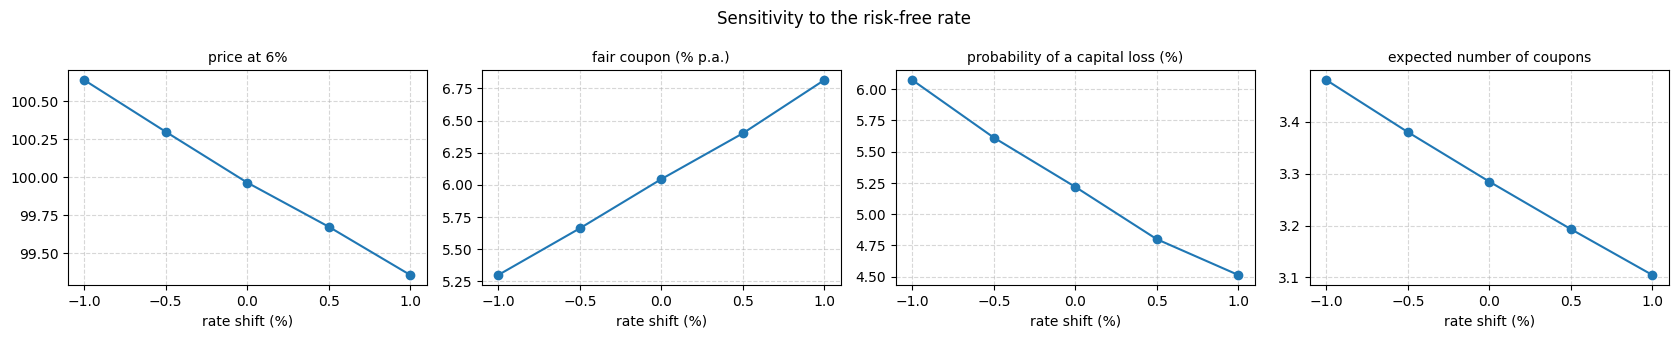

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),expected number of coupons
rate shift (%),,,,,,
-1,100.639,5.29678,53.88,6.072,1.10771,3.48042
-0.5,100.298,5.66017,54.67,5.612,1.06878,3.38014
0,99.9631,6.04354,55.428,5.218,1.03247,3.28464
0.5,99.6722,6.40033,56.198,4.8,0.99699,3.19314
1,99.3543,6.81558,56.952,4.514,0.96352,3.10474


In [16]:
rate_sweep = market_sweep("rate shift (%)", {d: (bump_rate(heston, d / 100), pricer) for d in [-1, -0.5, 0, 0.5, 1]})
plot_market_sweep(rate_sweep, "Sensitivity to the risk-free rate")
rate_sweep

#### Issuer spread

The cash flows are discounted at $r(t) + s$, the drift of the index being unchanged (control variate switched off).

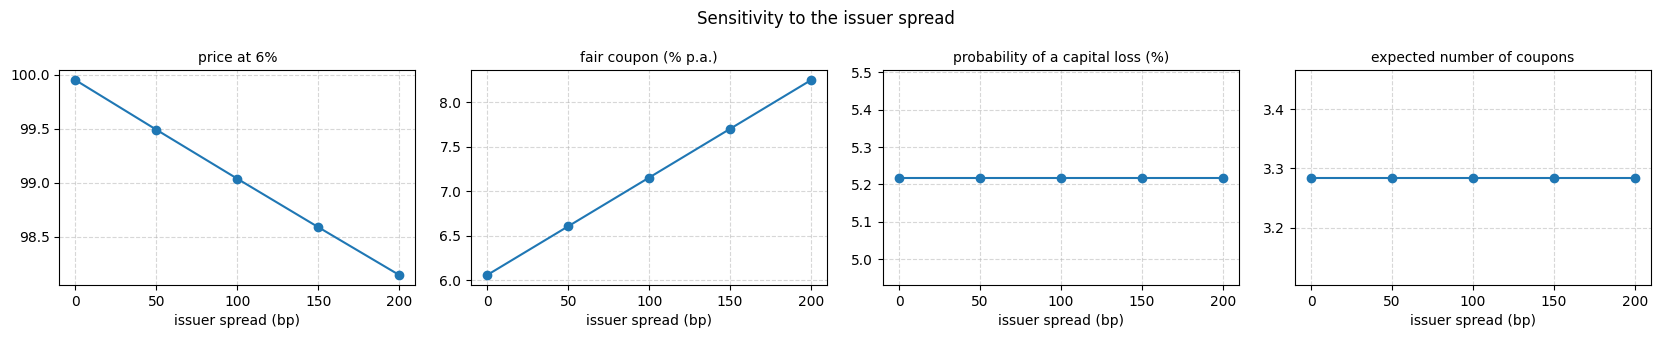

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),expected number of coupons
issuer spread (bp),,,,,,
0,99.949,6.06015,55.428,5.218,1.03247,3.28464
50,99.4899,6.60596,55.428,5.218,1.03247,3.28464
100,99.0365,7.15194,55.428,5.218,1.03247,3.28464
150,98.5885,7.6981,55.428,5.218,1.03247,3.28464
200,98.1459,8.24444,55.428,5.218,1.03247,3.28464


In [17]:
spread_sweep = market_sweep("issuer spread (bp)", {s: (heston, SpreadPricer(s / 1e4, n_paths=50_000, steps_per_year=52, seed=42)) for s in [0, 50, 100, 150, 200]})
plot_market_sweep(spread_sweep, "Sensitivity to the issuer spread")
spread_sweep

#### Maturity

Same note with a maturity from 1 to 5 years.

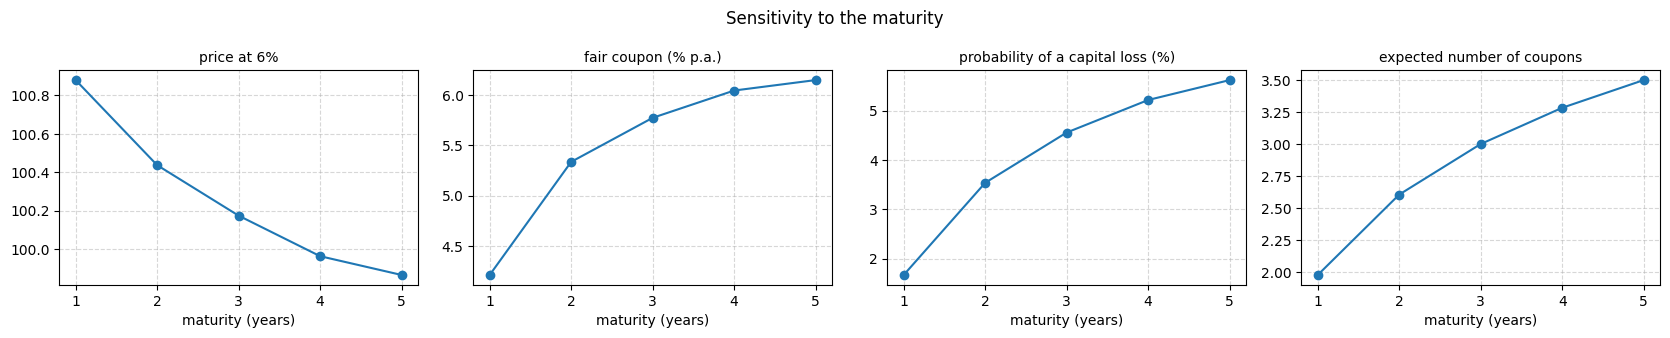

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),expected number of coupons
maturity (years),,,,,,
1,100.88,4.21099,55.428,1.668,0.51551,1.9756
2,100.437,5.33486,55.428,3.538,0.725965,2.60528
3,100.174,5.77245,55.428,4.558,0.89014,3.00116
4,99.9631,6.04354,55.428,5.218,1.03247,3.28464
5,99.8653,6.1474,55.428,5.622,1.16111,3.50164


In [18]:
maturity_sweep = market_sweep("maturity (years)", {T: (heston, pricer) for T in [1, 2, 3, 4, 5]},
                              note=lambda T: Phoenix(float(T), S0, 0.06, **BASE_TERMS))
plot_market_sweep(maturity_sweep, "Sensitivity to the maturity")
maturity_sweep

#### Skew (spot-volatility correlation)

The spot-variance correlation $\rho$ (calibrated at $-0.605$) is moved alone. The price of the 4-year European put struck at 60% (in % of $S_0$) measures how expensive the low strikes become.

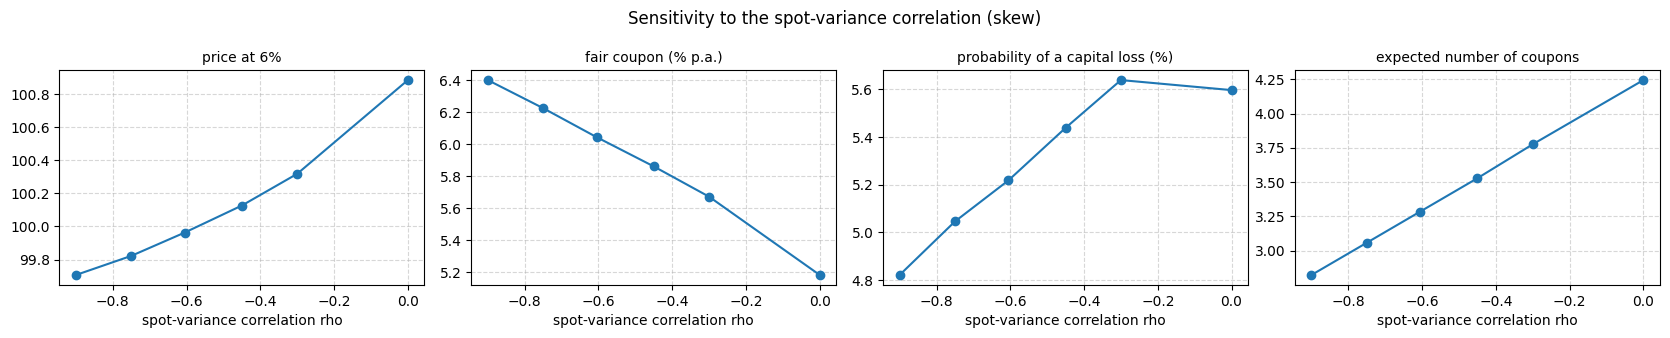

,price at 6%,fair coupon (% p.a.),call at 1st date (%),probability of a capital loss (%),expected life (years),expected number of coupons,4y put 60% price
spot-variance correlation rho,,,,,,,
-0.9,99.7064,6.40075,59.968,4.822,0.906875,2.8216,2.38609
-0.75,99.8219,6.22506,57.68,5.046,0.97185,3.05696,2.28177
-0.605,99.9631,6.04354,55.428,5.218,1.03247,3.28464,2.16812
-0.45,100.127,5.86024,53.162,5.438,1.09624,3.52786,2.03193
-0.3,100.319,5.67063,51.008,5.638,1.16178,3.77544,1.88467
0,100.886,5.18048,46.892,5.596,1.27872,4.24398,1.53951


In [19]:
skew_sweep = market_sweep("spot-variance correlation rho", {rho: (with_rho(rho), pricer) for rho in [-0.9, -0.75, -0.605, -0.45, -0.3, 0.0]})
skew_sweep["4y put 60% price"] = [float(with_rho(r).price_vanillas([0.6 * S0], 4.0, False)[0]) / S0 * 100 for r in skew_sweep.index]
plot_market_sweep(skew_sweep, "Sensitivity to the spot-variance correlation (skew)")
skew_sweep

### 3.5 Hedging

The issuer is short the note : it is long the down-and-in put sold by the investor and short the strip of conditional coupons and the autocall feature. We compute the Greeks of the base case as functions of the spot, the initial fixing staying at $S_0$, and the hedge of the issuer at inception.

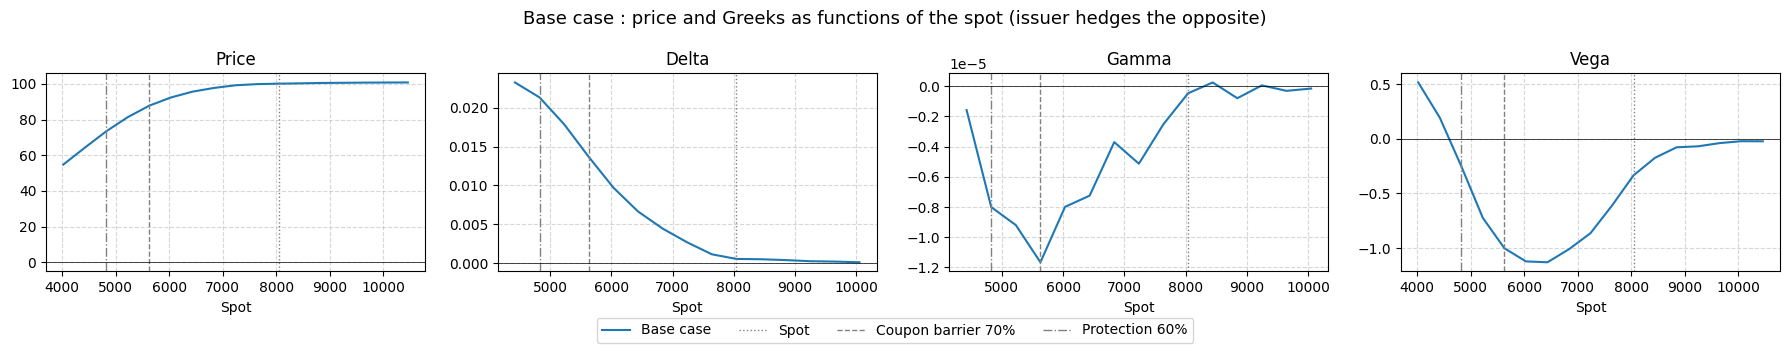

,price,delta,gamma,vega,rho,theta
spot,,,,,,
4021.09,54.7633,NaN,NaN,0.514843,1.51201,0.000911278
4423.2,64.2369,0.0232425,-1.57705e-06,0.192815,1.49486,0.00341295
4825.31,73.4554,0.0213155,-8.0078e-06,-0.252071,0.95931,0.00537999
5227.42,81.3792,0.0178553,-9.20203e-06,-0.724729,0.24646,0.0073509
5629.53,87.815,0.0136593,-1.16682e-05,-1.00214,-0.359598,0.00995846
6031.64,92.3642,0.00970616,-7.99381e-06,-1.12259,-1.02548,0.0100421
6433.75,95.6209,0.0066414,-7.24963e-06,-1.13063,-1.28341,0.00816886
6835.86,97.7054,0.00444008,-3.69923e-06,-1.01113,-1.38812,0.0093566
7237.97,99.1917,0.00266485,-5.13035e-06,-0.864123,-1.27988,0.0146961


In [20]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=52, seed=42)
spots = S0 * np.linspace(0.5, 1.3, 17)
base_profiles = Greeks(profile_pricer).profiles(heston, [base], spots, greeks=("delta", "gamma", "vega", "rho", "theta"), labels=["Base case"])
plot_greek_profiles(base_profiles, greeks=("price", "delta", "gamma", "vega"), vlines={"Spot": S0, "Coupon barrier 70%": 0.7 * S0, "Protection 60%": 0.6 * S0},
                    title="Base case : price and Greeks as functions of the spot (issuer hedges the opposite)")
base_profiles["Base case"]

In [21]:
# Hedge of the issuer at inception, for a nominal of 100 : it is short the note, so it holds the opposite of its Greeks.
g = Greeks(pricer).compute(heston, base, ("delta", "vega", "rho", "dividend"))["value"]
K = 0.6 * S0
put = lambda m: float(m.price_vanillas([K], 4.0, False)[0])
put_vega = (put(bump_vol(heston, 0.01)) - put(bump_vol(heston, -0.01))) / 2        # per vol point, per unit of index
hedge = pd.Series({
    "note delta (per index point)": g["delta"],
    "index exposure of the note (% nominal)": 100 * g["delta"] * S0 / 100,
    "note vega (per vol point)": g["vega"],
    "4y 60% put vega (per vol point, per unit)": put_vega,
    "issuer : 4y 60% puts to sell (units)": -g["vega"] / put_vega,
    "note rho (per +1%)": g["rho"],
    "note dividend (per +1%)": g["dividend"],
}, name="Base case")
hedge.to_frame()

,Base case
note delta (per index point),0.000586197
index exposure of the note (% nominal),4.71431
note vega (per vol point),-0.334505
"4y 60% put vega (per vol point, per unit)",19.3163
issuer : 4y 60% puts to sell (units),0.0173172
note rho (per +1%),-0.599297
note dividend (per +1%),-0.324995


**Reading.** At inception, the delta of the Phoenix is almost zero : a higher spot reduces the short put, but it also brings the call forward and removes coupons. The delta is not stable : when the index falls towards the coupon and protection barriers, the call becomes unlikely, the put gets closer to the money and the delta of the note increases, so the issuer must buy index in a falling market. The issuer is long volatility and long dividends : it hedges the vega with listed puts around the protection barrier and the dividends with dividend futures. Close to maturity, the jumps of the payoff at the coupon barrier and at the protection barrier make the delta and the gamma very large around these levels (pin risk).

## 4. Features of Phoenix products

We now look at the features that can be added to the Phoenix product and at their impact on the price. Every variant is compared with the base case, all the other terms being equal.

### 4.1 Observation frequency

The coupon and autocall barriers are now observed every day (1008 observation dates, a daily coupon of $c / 252$) instead of every quarter. The daily grid is needed, since the weekly one is too coarse for these dates.

In [22]:
compare("Daily observation", Phoenix(4.0, S0, 0.06, frequency=1/252, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6), daily_pricer)

Base case Daily observation
Contract  number of observations                       16              1008
          observation frequency (years)              0.25        0.00396825
          first call date (years)                    0.25        0.00396825
Pricing   price                                   99.9631           99.9429
          95% confidence (+/-)                  0.0985235         0.0438577
          price (% nominal)                       99.9631           99.9429
          fair coupon (% p.a.)                    6.04354           6.52173
Scenarios probability to reach maturity            0.1329           0.01796
          probability of a capital loss           0.05218           0.00778
          expected loss at maturity (% nominal)   3.05192          0.455526
          expected life (years)                   1.03247          0.134455
          expected number of coupons              3.28464           25.9686
          expected coupon paid (% nominal)        5.23461           0.67462

In [23]:
# observation frequency : annual, semi-annual and monthly (quarterly is the base case)
for name, f in [("Annual observation", 1.0), ("Semi-annual observation", 0.5), ("Monthly observation", 1 / 12)]:
    reports[name] = Phoenix(4.0, S0, 0.06, **{**BASE_TERMS, "frequency": f}).report(pricer, heston, name=name)
frequency_names = ["Annual observation", "Semi-annual observation", "Base case", "Monthly observation", "Daily observation"]
pd.concat([reports[n] for n in frequency_names], axis=1).drop(index="Contract", level=0)

Annual observation  \
Pricing   price                                            100.618   
          95% confidence (+/-)                            0.109856   
          price (% nominal)                                100.618   
          fair coupon (% p.a.)                             5.62862   
Scenarios probability to reach maturity                    0.25704   
          probability of a capital loss                     0.0906   
          expected loss at maturity (% nominal)            5.27305   
          expected life (years)                            2.06456   
          expected number of coupons                       1.66952   
          expected coupon paid (% nominal)                 10.3933   

                                                Semi-annual observation  \
Pricing   price                                                 100.217   
          95% confidence (+/-)                                 0.106225   
          price (% nominal)                                     100.217   
          fair coupon (% p.a.)                                  5.82004   
Scenarios probability to reach maturity                          0.1861   
          probability of a capital loss                         0.06972   
          expected loss at maturity (% nominal)                 4.07502   
          expected life (years)                                 1.47667   
          expected number of coupons                            2.37514   
          expected coupon paid (% nominal)                       7.4868   

                                                Base case Monthly observation  \
Pricing   price                                   99.9631             99.9073   
          95% confidence (+/-)                  0.0985235           0.0820477   
          price (% nominal)                       99.9631             99.9073   
          fair coupon (% p.a.)                    6.04354             6.19164   
Scenarios probability to reach maturity            0.1329             0.07766   
          probability of a capital loss           0.05218             0.03128   
          expected loss at maturity (% nominal)   3.05192             1.83039   
          expected life (years)                   1.03247            0.588053   
          expected number of coupons              3.28464             5.52976   
          expected coupon paid (% nominal)        5.23461             2.98386   

                                                Daily observation  
Pricing   price                                           99.9429  
          95% confidence (+/-)                          0.0438577  
          price (% nominal)                               99.9429  
          fair coupon (% p.a.)                            6.52173  
Scenarios probability to reach maturity                   0.01796  
          probability of a capital loss                   0.00778  
          expected loss at maturity (% nominal)          0.455526  
          expected life (years)                          0.134455  
          expected number of coupons                      25.9686  
          expected coupon paid (% nominal)                0.67462

### 4.2 Memory

Without memory, a coupon missed because the index was below the coupon barrier is lost for good.

In [24]:
compare("No memory", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, memory=False))

Base case No memory
Contract  memory                                     True     False
Pricing   price                                   99.9631    99.673
          95% confidence (+/-)                  0.0985235 0.0984946
          price (% nominal)                       99.9631    99.673
          fair coupon (% p.a.)                    6.04354   6.40934
Scenarios probability to reach maturity            0.1329    0.1329
          probability of a capital loss           0.05218   0.05218
          expected loss at maturity (% nominal)   3.05192   3.05192
          expected life (years)                   1.03247   1.03247
          expected number of coupons              3.28464   3.28464
          expected coupon paid (% nominal)        5.23461   4.92696

### 4.3 Step-down barrier

The autocall barrier decreases by 1% at each observation, from 100% to 85% at maturity. The call becomes easier over time.

In [25]:
compare("Step-down 1%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, step_down=0.01))

Base case Step-down 1%
Contract  last autocall barrier (%)                   100           85
          step-down per observation (%)                 0            1
Pricing   price                                   99.9631      99.8872
          95% confidence (+/-)                  0.0985235    0.0936992
          price (% nominal)                       99.9631      99.8872
          fair coupon (% p.a.)                    6.04354      6.15838
Scenarios probability to reach maturity            0.1329      0.08118
          probability of a capital loss           0.05218       0.0444
          expected loss at maturity (% nominal)   3.05192      2.61864
          expected life (years)                   1.03247       0.8738
          expected number of coupons              3.28464      2.73314
          expected coupon paid (% nominal)        5.23461      4.37979

### 4.4 Airbag

The put is struck at the protection barrier : below 60%, the redemption is $100 \, S_T / (0.6 \, S_{ref})$. There is no more loss jump at the barrier.

In [26]:
compare("Airbag", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, put_strike=0.6))

Base case    Airbag
Contract  redemption if knocked-in               standard    airbag
Pricing   price                                   99.9631   101.278
          95% confidence (+/-)                  0.0985235 0.0659839
          price (% nominal)                       99.9631   101.278
          fair coupon (% p.a.)                    6.04354   4.49177
Scenarios probability to reach maturity            0.1329    0.1329
          probability of a capital loss           0.05218   0.05218
          expected loss at maturity (% nominal)   3.05192   1.60787
          expected life (years)                   1.03247   1.03247
          expected number of coupons              3.28464   3.28464
          expected coupon paid (% nominal)        5.23461   5.23461

### 4.5 Buffer

The first 10% of decline is absorbed by the issuer : below 90%, the investor loses one for one, $100 \, (S_T / S_{ref} + 10\%)$, without loss jump.

In [27]:
compare("Buffer 10%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.9, buffer=0.1))

Base case  Buffer 10%
Contract  protection barrier (%)                       60          90
          redemption if knocked-in               standard  buffer 10%
          buffer (%)                                    0          10
Pricing   price                                   99.9631     99.5352
          95% confidence (+/-)                  0.0985235   0.0848592
          price (% nominal)                       99.9631     99.5352
          fair coupon (% p.a.)                    6.04354     6.54872
Scenarios probability to reach maturity            0.1329      0.1329
          probability of a capital loss           0.05218     0.11808
          expected loss at maturity (% nominal)   3.05192     3.50149
          expected life (years)                   1.03247     1.03247
          expected number of coupons              3.28464     3.28464
          expected coupon paid (% nominal)        5.23461     5.23461

### 4.6 Guaranteed capital

The redemption at maturity is floored : `floor=1.0` guarantees 100% of the capital, `floor=0.9` guarantees 90%.

In [28]:
compare("Guaranteed 100%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, floor=1.0))

Base case Guaranteed 100%
Contract  capital guaranteed (%)                        0             100
Pricing   price                                   99.9631         102.736
          95% confidence (+/-)                  0.0985235       0.0310943
          price (% nominal)                       99.9631         102.736
          fair coupon (% p.a.)                    6.04354         2.76992
Scenarios probability to reach maturity            0.1329          0.1329
          probability of a capital loss           0.05218               0
          expected loss at maturity (% nominal)   3.05192               0
          expected life (years)                   1.03247         1.03247
          expected number of coupons              3.28464         3.28464
          expected coupon paid (% nominal)        5.23461         5.23461

In [29]:
compare("Guaranteed 90%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, floor=0.9))

Base case Guaranteed 90%
Contract  capital guaranteed (%)                        0             90
Pricing   price                                   99.9631        102.262
          95% confidence (+/-)                  0.0985235      0.0373701
          price (% nominal)                       99.9631        102.262
          fair coupon (% p.a.)                    6.04354        3.33004
Scenarios probability to reach maturity            0.1329         0.1329
          probability of a capital loss           0.05218        0.05218
          expected loss at maturity (% nominal)   3.05192         0.5218
          expected life (years)                   1.03247        1.03247
          expected number of coupons              3.28464        3.28464
          expected coupon paid (% nominal)        5.23461        5.23461

### 4.7 Coupon range accrual

The coupon of each quarter only accrues on the (weekly) simulation dates where $80\% \leq S_t / S_{ref} \leq 120\%$. It is still paid only if the index is above the coupon barrier at the observation date (`coupon_barrier=0` would give a pure range accrual).

In [30]:
compare("Range accrual 80-120%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, accrual_range=(0.8, 1.2)))

Base case  \
Contract  range accrual (%)                          none   
Pricing   price                                   99.9631   
          95% confidence (+/-)                  0.0985235   
          price (% nominal)                       99.9631   
          fair coupon (% p.a.)                    6.04354   
Scenarios probability to reach maturity            0.1329   
          probability of a capital loss           0.05218   
          expected loss at maturity (% nominal)   3.05192   
          expected life (years)                   1.03247   
          expected number of coupons              3.28464   
          expected coupon paid (% nominal)        5.23461   

                                                Range accrual 80-120%  
Contract  range accrual (%)                                 [80, 120]  
Pricing   price                                               99.0234  
          95% confidence (+/-)                               0.099797  
          price (% nominal)                                   99.0234  
          fair coupon (% p.a.)                                7.41432  
Scenarios probability to reach maturity                        0.1329  
          probability of a capital loss                       0.05218  
          expected loss at maturity (% nominal)               3.05192  
          expected life (years)                               1.03247  
          expected number of coupons                          3.28464  
          expected coupon paid (% nominal)                    4.24555

### 4.8 Duo mechanism

Two call levels : above 100%, the note is called with the coupon of the date ; between 90% and 100%, it is also called, but the coupon of the date (with the memory) is halved.

In [31]:
compare("Duo 90% / 50%", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, duo_barrier=0.9, duo_coupon_ratio=0.5))

Base case Duo 90% / 50%
Contract  duo barrier (%)                            none            90
          duo coupon ratio                           none           0.5
Pricing   price                                   99.9631       99.8933
          95% confidence (+/-)                  0.0985235     0.0646141
          price (% nominal)                       99.9631       99.8933
          fair coupon (% p.a.)                    6.04354       6.34829
Scenarios probability to reach maturity            0.1329       0.03132
          probability of a capital loss           0.05218       0.01704
          expected loss at maturity (% nominal)   3.05192       1.00956
          expected life (years)                   1.03247       0.42151
          expected number of coupons              3.28464         1.373
          expected coupon paid (% nominal)        5.23461       1.87106

### 4.9 Look back

The reference level $S_{ref}$ is the minimum of the index over the first month instead of the initial fixing (`lookback_type='average'` gives an Asian fixing).

In [32]:
compare("Look back min 1m", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, lookback=1/12, lookback_type='min'))

Base case     Look back min 1m
Contract  look back                                  none  min over 0.0833333y
Pricing   price                                   99.9631              100.203
          95% confidence (+/-)                  0.0985235            0.0856688
          price (% nominal)                       99.9631              100.203
          fair coupon (% p.a.)                    6.04354              5.68756
Scenarios probability to reach maturity            0.1329               0.0903
          probability of a capital loss           0.05218              0.03572
          expected loss at maturity (% nominal)   3.05192              2.08984
          expected life (years)                   1.03247             0.778975
          expected number of coupons              3.28464               2.5319
          expected coupon paid (% nominal)        5.23461              4.00665

### 4.10 Protection type

The protection is now American : the capital is at risk as soon as the index touches 60% at any time before maturity, continuously (Brownian bridge on the weekly grid) or on daily closes (daily grid).

In [33]:
compare("American protection", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, protection_type="american"))

Base case American protection
Contract  protection type                        european            american
Pricing   price                                   99.9631             98.9975
          95% confidence (+/-)                  0.0985235            0.103325
          price (% nominal)                       99.9631             98.9975
          fair coupon (% p.a.)                    6.04354              7.1834
Scenarios probability to reach maturity            0.1329              0.1329
          probability of a capital loss           0.05218           0.0921762
          expected loss at maturity (% nominal)   3.05192             4.10912
          expected life (years)                   1.03247             1.03247
          expected number of coupons              3.28464             3.28464
          expected coupon paid (% nominal)        5.23461             5.23461

In [34]:
compare("American protection (daily)", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, protection_type="american_discrete"), daily_pricer)

Base case  \
Contract  protection type                        european   
Pricing   price                                   99.9631   
          95% confidence (+/-)                  0.0985235   
          price (% nominal)                       99.9631   
          fair coupon (% p.a.)                    6.04354   
Scenarios probability to reach maturity            0.1329   
          probability of a capital loss           0.05218   
          expected loss at maturity (% nominal)   3.05192   
          expected life (years)                   1.03247   
          expected number of coupons              3.28464   
          expected coupon paid (% nominal)        5.23461   

                                                American protection (daily)  
Contract  protection type                                 american_discrete  
Pricing   price                                                     99.0662  
          95% confidence (+/-)                                     0.104244  
          price (% nominal)                                         99.0662  
          fair coupon (% p.a.)                                      7.10531  
Scenarios probability to reach maturity                             0.13226  
          probability of a capital loss                              0.0898  
          expected loss at maturity (% nominal)                        4.06  
          expected life (years)                                     1.03146  
          expected number of coupons                                3.27648  
          expected coupon paid (% nominal)                          5.21961

### 4.11 Non-call period

The note cannot be called during the first year : the first callable date is $t = 1$ (the coupons are still paid).

In [35]:
compare("Non-call 1 year", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, first_call_date=1.0))

Base case Non-call 1 year
Contract  first call date (years)                    0.25               1
Pricing   price                                   99.9631         100.864
          95% confidence (+/-)                  0.0985235        0.104528
          price (% nominal)                       99.9631         100.864
          fair coupon (% p.a.)                    6.04354         5.45522
Scenarios probability to reach maturity            0.1329         0.22064
          probability of a capital loss           0.05218         0.08416
          expected loss at maturity (% nominal)   3.05192         4.91549
          expected life (years)                   1.03247         1.88512
          expected number of coupons              3.28464         6.21498
          expected coupon paid (% nominal)        5.23461         9.80616

### 4.12 Unconditional coupon

With a coupon barrier at 0, the coupon is paid at every date until the call, whatever the level of the index (fixed coupon).

In [36]:
compare("Unconditional coupon", Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.0, autocall_barrier=1.0, protection_barrier=0.6))

Base case Unconditional coupon
Contract  first coupon barrier (%)                     70                    0
          last coupon barrier (%)                      70                    0
Pricing   price                                   99.9631              100.867
          95% confidence (+/-)                  0.0985235            0.0770096
          price (% nominal)                       99.9631              100.867
          fair coupon (% p.a.)                    6.04354              5.13072
Scenarios probability to reach maturity            0.1329               0.1329
          probability of a capital loss           0.05218              0.05218
          expected loss at maturity (% nominal)   3.05192              3.05192
          expected life (years)                   1.03247              1.03247
          expected number of coupons              3.28464              4.12988
          expected coupon paid (% nominal)        5.23461              6.19482

### 4.13 Summary

All the variants priced above, with a coupon of 6% p.a. :

In [37]:
summary = pd.concat(reports.values(), axis=1).drop(index="Contract", level=0).droplevel(0).T.astype(float)
summary = summary.drop(columns=["price (% nominal)"])
summary.sort_values("fair coupon (% p.a.)")

,price,95% confidence (+/-),fair coupon (% p.a.),probability to reach maturity,probability of a capital loss,expected loss at maturity (% nominal),expected life (years),expected number of coupons,expected coupon paid (% nominal)
Guaranteed 100%,102.736,0.0310943,2.76992,0.1329,0,0,1.03247,3.28464,5.23461
Guaranteed 90%,102.262,0.0373701,3.33004,0.1329,0.05218,0.5218,1.03247,3.28464,5.23461
Airbag,101.278,0.0659839,4.49177,0.1329,0.05218,1.60787,1.03247,3.28464,5.23461
Unconditional coupon,100.867,0.0770096,5.13072,0.1329,0.05218,3.05192,1.03247,4.12988,6.19482
Autocall 110%,101.4,0.105746,5.30854,0.37564,0.1048,6.03887,2.39018,8.03534,12.6113
Non-call 1 year,100.864,0.104528,5.45522,0.22064,0.08416,4.91549,1.88512,6.21498,9.80616
Annual observation,100.618,0.109856,5.62862,0.25704,0.0906,5.27305,2.06456,1.66952,10.3933
Look back min 1m,100.203,0.0856688,5.68756,0.0903,0.03572,2.08984,0.778975,2.5319,4.00665
Semi-annual observation,100.217,0.106225,5.82004,0.1861,0.06972,4.07502,1.47667,2.37514,7.4868
Base case,99.9631,0.0985235,6.04354,0.1329,0.05218,3.05192,1.03247,3.28464,5.23461


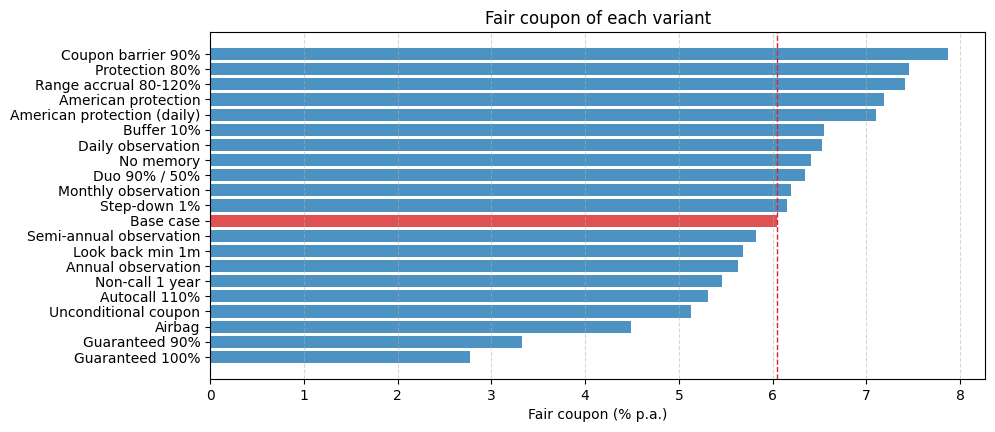

In [38]:
fair = summary["fair coupon (% p.a.)"].sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["tab:red" if name == "Base case" else "tab:blue" for name in fair.index]
ax.barh(fair.index, fair.values, color=colors, alpha=0.8)
ax.axvline(fair["Base case"], color="tab:red", linestyle="--", linewidth=1)
ax.set_xlabel("Fair coupon (% p.a.)")
ax.set_title("Fair coupon of each variant")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.show()

Redemption at maturity of the variants that change the capital protection, if the note was never called :

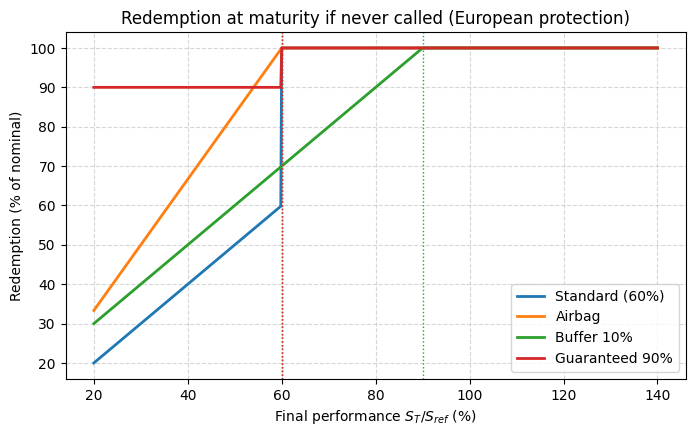

<Axes: title={'center': 'Redemption at maturity if never called (European protection)'}, xlabel='Final performance $S_T / S_{ref}$ (%)', ylabel='Redemption (% of nominal)'>

In [39]:
plot_redemption_profiles({
    "Standard (60%)": base,
    "Airbag": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, put_strike=0.6),
    "Buffer 10%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.9, buffer=0.1),
    "Guaranteed 90%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, floor=0.9),
})

Call probabilities of the variants that change the autocall mechanism :

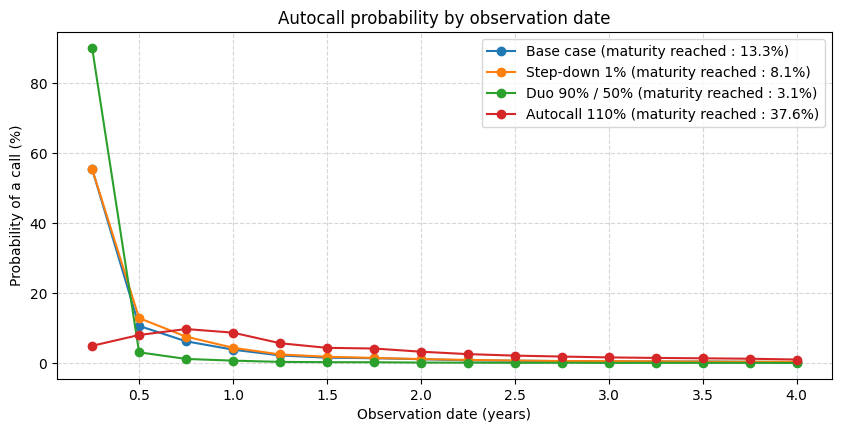

In [40]:
plot_call_probabilities(pricer, heston, {
    "Base case": base,
    "Step-down 1%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, step_down=0.01),
    "Duo 90% / 50%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, duo_barrier=0.9, duo_coupon_ratio=0.5),
    "Autocall 110%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.1, protection_barrier=0.6),
})

**Reading.** The features that reduce the loss at maturity (guaranteed capital, airbag) or the probability of the loss (look back) are more valuable for the investor, so their fair coupon is lower than in the base case. The features that make the loss more likely (higher protection barrier, buffer, which starts losing below 90%) or the coupon smaller (no memory, range accrual, higher coupon barrier) are paid by a higher fair coupon.

The features that make the call easier (step-down, duo, daily observation) behave the opposite way to the Athena : they shorten the life of the note, so fewer coupons are paid and a higher coupon rate is needed, although the loss is less likely. Conversely, a higher autocall barrier lowers the fair coupon of the Phoenix. The Phoenix investor is mainly long a strip of conditional coupons, whose value grows with the life of the note, whereas the Athena investor receives a single coupon at the call.

## 5. Greeks

Greeks of the base case and of the variants that change the capital protection or the coupon, by finite differences on the same paths (delta per unit of spot, vega per vol point, rho per +1% of rates, theta per day).

In [41]:
greek_notes = {
    "Base case": base,
    "American protection": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, protection_type="american"),
    "Step-down 1%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, step_down=0.01),
    "Airbag": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, put_strike=0.6),
    "Guaranteed 90%": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, floor=0.9),
    "No memory": Phoenix(4.0, S0, 0.06, frequency=0.25, coupon_barrier=0.7, autocall_barrier=1.0, protection_barrier=0.6, memory=False),
}
greeks = Greeks(pricer).table(heston, list(greek_notes.values()), labels=list(greek_notes), with_stderr=True,
                              greeks=("delta", "gamma", "vega", "vanna", "volga", "rho", "dividend", "theta"))
greeks["delta 1%"] = greeks["delta"] * S0 / 100                       # value change of a 1% move of the index
greeks[[c for c in greeks.columns if not c.endswith("stderr")]]

,price,delta,gamma,vega,vanna,volga,rho,dividend,theta,delta 1%
Base case,99.9631,0.000586197,-1.22335e-06,-0.334505,0.000613201,-0.00490519,-0.599297,-0.324995,0.00495895,0.0471431
American protection,98.9975,0.00228991,-2.68688e-06,-0.394419,0.000572497,0.0120855,-0.448074,-0.437417,0.00389752,0.184159
Step-down 1%,99.8872,0.000457058,-3.26991e-06,-0.269809,0.00033658,-0.00112976,-0.579026,-0.198397,0.00317714,0.0367575
Airbag,101.278,-0.00150825,1.14673e-06,-0.224196,0.000538226,-0.00573996,-0.875196,-0.101446,0.00263302,-0.121297
Guaranteed 90%,102.262,-0.00297442,3.62241e-06,-0.0855052,0.000437472,0.0059155,-1.07278,0.0566232,0.00209742,-0.239208
No memory,99.673,0.00105775,-1.27217e-06,-0.364836,0.000627206,-0.002512,-0.560149,-0.356628,0.00533534,0.0850659


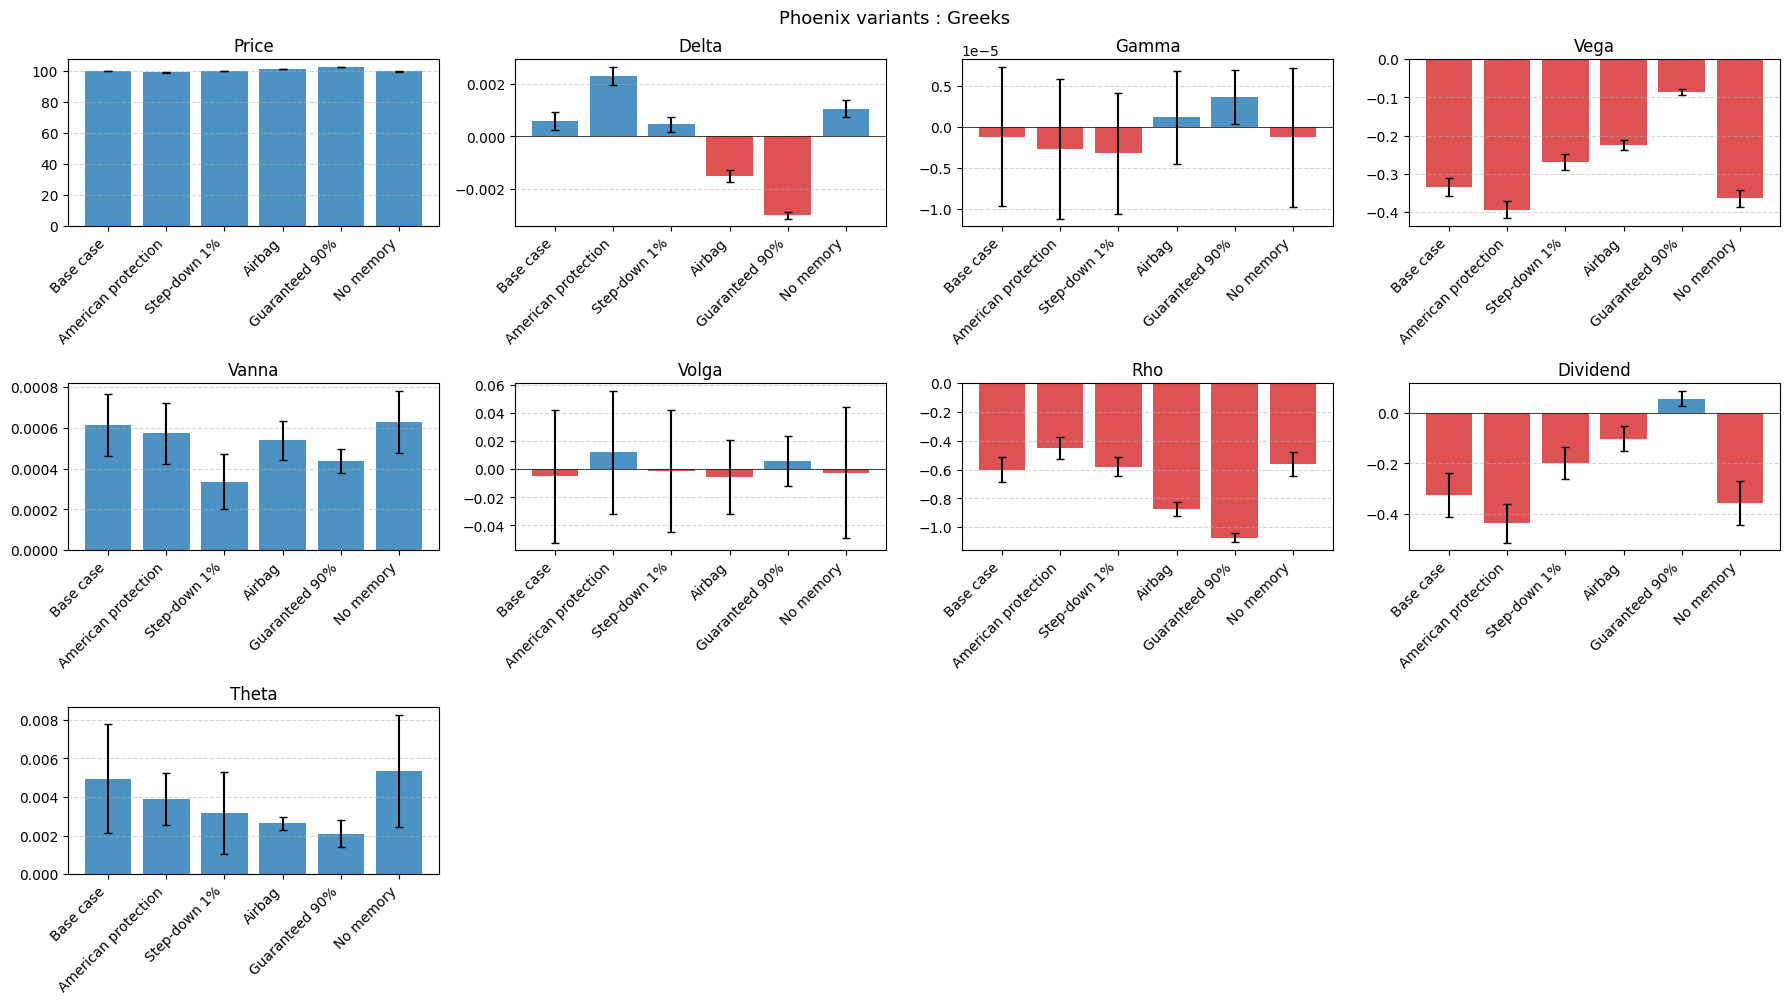

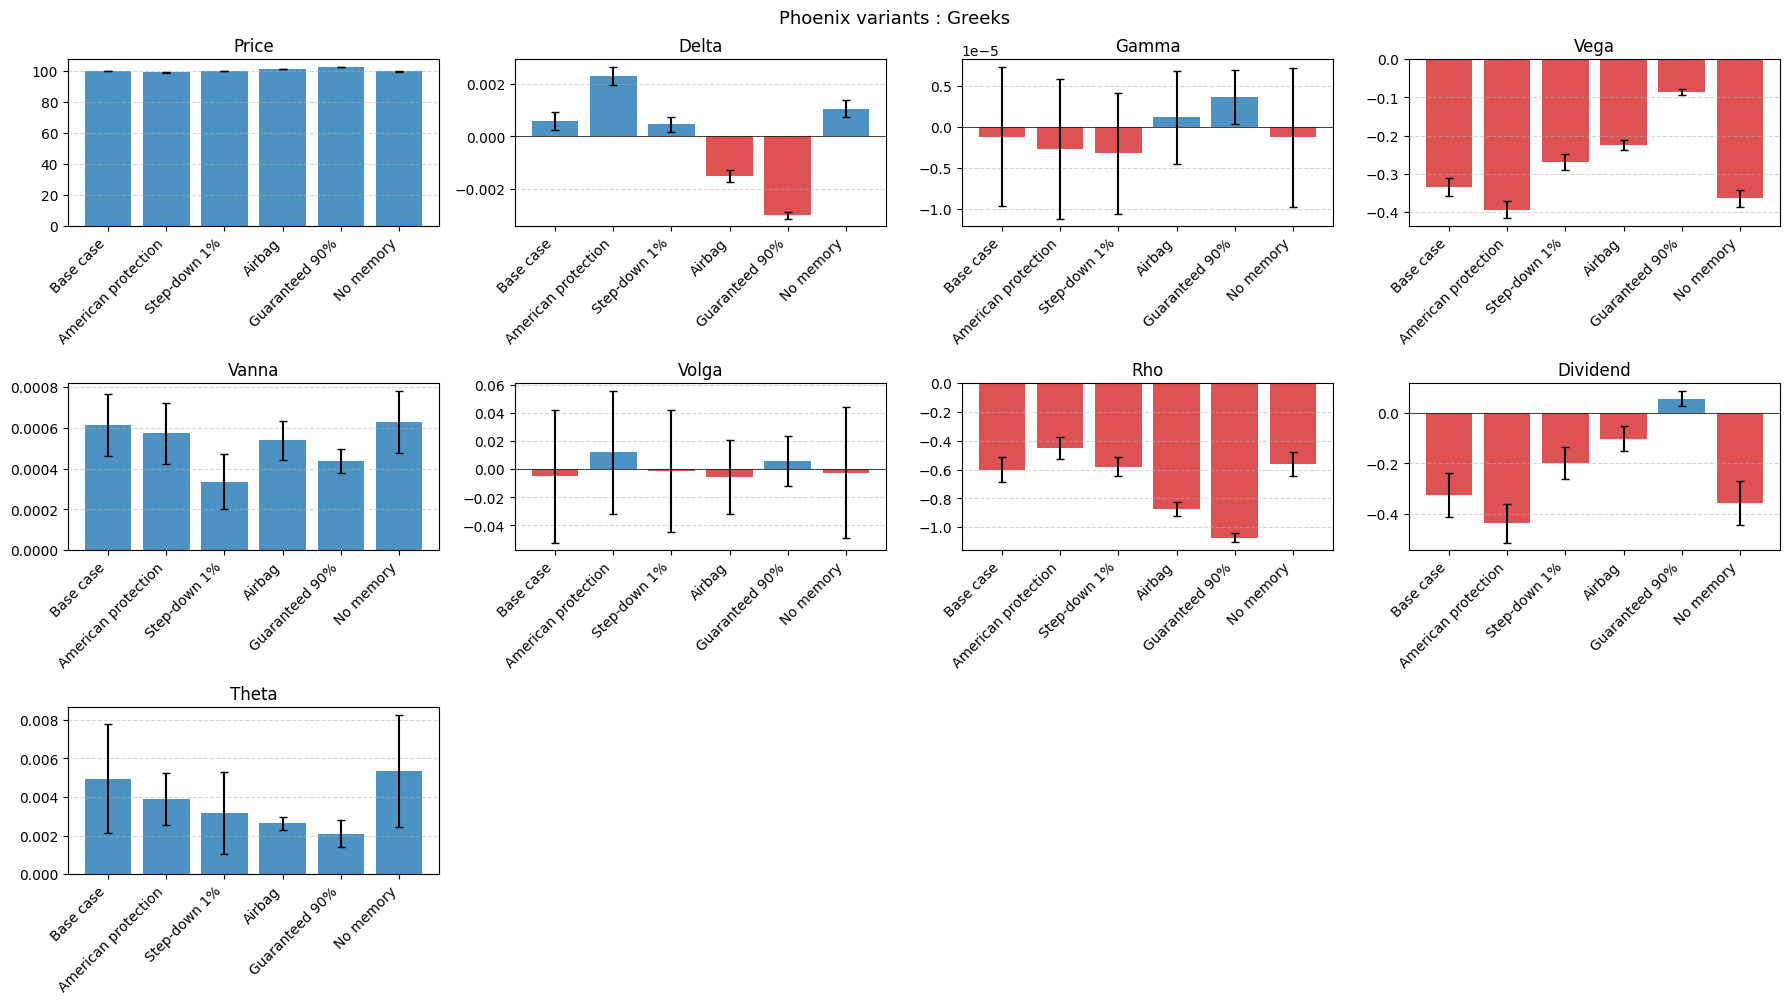

In [42]:
plot_greeks_bars(greeks, greeks=("price", "delta", "gamma", "vega", "vanna", "volga", "rho", "dividend", "theta"), title="Phoenix variants : Greeks")

In [43]:
# standard errors of the base case, and sensitivities to the Heston parameters (per unit of parameter)
display(greeks.loc["Base case", [c for c in greeks.columns if c.endswith("stderr")]].to_frame())
Greeks(pricer).parameter_sensitivities(heston, base)

,Base case
price stderr,0.0502671
delta stderr,0.000170764
gamma stderr,4.34626e-06
vega stderr,0.0118819
vanna stderr,7.82978e-05
volga stderr,0.024139
rho stderr,0.0441925
dividend stderr,0.0441318
theta stderr,0.00143591


,value,stderr
d/dv0,-40.3525,12.2114
d/dtheta,-44.8981,7.40401
d/dkappa,-0.192561,0.207141
d/dxi,1.36478,0.984907
d/drho,0.869389,0.682568


**Reading.** The investor is short volatility (negative vega) : a higher volatility makes the knock-in more likely and the coupons less certain. The delta of the base case is close to zero, because two effects offset each other : a higher spot reduces the value of the short put, but it also brings the call forward and removes coupons. When the put is reduced (airbag) or almost removed (guaranteed 90%), the second effect wins and the delta becomes negative. Flooring the capital also shrinks the vega and makes the note behave more like a bond, with a more negative rho.